# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [2]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [3]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [4]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('suck')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [5]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [6]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: west
step 1 - action: north
step 2 - action: south
step 3 - action: suck
step 4 - action: south
step 5 - action: west
step 6 - action: north
step 7 - action: west
step 8 - action: west
step 9 - action: north
step 10 - action: west
step 11 - action: east
step 12 - action: north
step 13 - action: north
step 14 - action: north
step 15 - action: west
step 16 - action: west
step 17 - action: suck
step 18 - action: west
step 19 - action: west


2

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

**Thiết kế của em:** `vacuum_environment` lưu trạng thái phòng bằng một mảng boolean `n x n` (`True` = bẩn). Ở mỗi bước, hàm tính 4 cảm biến va chạm dựa trên vị trí hiện tại so với biên phòng, đọc cảm biến bụi tại ô hiện tại, gọi `agent_function(bumpers, dirty)` để lấy hành động, rồi cập nhật trạng thái phòng/vị trí tương ứng. Vòng lặp dừng ngay khi cả phòng sạch (trả về đúng số hành động đã dùng = performance measure theo PEAS) hoặc khi hết `max_steps` (trả `np.nan` để biểu thị tác tử không đủ năng lượng hoàn thành).

In [7]:
def vacuum_environment(agent_function, n=5, p=0.2, max_steps=1000, verbose=False, render=False):
    """
    Simulate the cleaning phase of a vacuum-cleaner robot in an n x n room,
    following the PEAS description above.

    Parameters
    ----------
    agent_function : function(bumpers, dirty) -> action
        The agent program under test.
    n : int
        Size of the (square) room, n x n squares.
    p : float
        Probability that a square starts out dirty.
    max_steps : int
        Energy budget (maximum number of actions) available to the agent.
    verbose : bool
        If True, print one line per step with the current percepts and action.
    render : bool
        If True (and verbose), also draw the room as an ASCII grid every step.
        Only useful for small n -- do not use this for large simulation studies.

    Returns
    -------
    int or float
        The number of actions (= energy units) used to clean the whole room
        (this is exactly the performance measure defined in the PEAS description).
        Returns np.nan if the agent ran out of energy (max_steps) before the
        whole room was clean.
    """
    # room[row, col] == True means the square is dirty
    room = np.random.rand(n, n) < p
    # the agent starts on a random square
    pos = np.random.randint(0, n, size=2)

    def get_bumpers(pos):
        return {
            "north": bool(pos[0] == 0),
            "south": bool(pos[0] == n - 1),
            "west": bool(pos[1] == 0),
            "east": bool(pos[1] == n - 1),
        }

    def draw(pos):
        grid = np.where(room, '*', '.')
        grid[pos[0], pos[1]] = 'A'
        print("\n".join("".join(row) for row in grid))

    for step in range(max_steps):
        # the cleaning phase ends as soon as the whole room is clean
        if not room.any():
            return step

        bumpers = get_bumpers(pos)
        dirty = bool(room[pos[0], pos[1]])
        action = agent_function(bumpers, dirty)

        if action == "suck":
            room[pos[0], pos[1]] = False
        elif action in ("north", "south", "east", "west"):
            if not bumpers[action]:  # ignore the move if it would bump into a wall
                if action == "north":
                    pos[0] -= 1
                elif action == "south":
                    pos[0] += 1
                elif action == "west":
                    pos[1] -= 1
                elif action == "east":
                    pos[1] += 1
        else:
            raise ValueError(f"Unknown action returned by agent: {action}")

        if verbose:
            print(f"step {step:4d}: pos={tuple(int(x) for x in pos)} dirty={dirty} "
                  f"-> action={action:6s} | dirty squares left: {int(room.sum())}")
            if render:
                draw(pos)
                print()

    # ran out of energy before the room was fully clean
    if verbose:
        print(f"Agent ran out of energy after {max_steps} steps; "
              f"{int(room.sum())} squares are still dirty.")
    return np.nan


Show that your environment works with the simple randomized agent from above.

In [8]:
# Demonstration: run the environment with the simple randomized agent from above,
# on a small 5x5 room so the printed grid stays readable.
np.random.seed(1)
result = vacuum_environment(simple_randomized_agent, n=5, p=0.2, max_steps=15,
                             verbose=True, render=True)
print("\nPerformance (energy used):", result)


step    0: pos=(3, 1) dirty=False -> action=north  | dirty squares left: 7
..*.*
**...
....*
.A.**
.....

step    1: pos=(2, 1) dirty=False -> action=north  | dirty squares left: 7
..*.*
**...
.A..*
...**
.....

step    2: pos=(3, 1) dirty=False -> action=south  | dirty squares left: 7
..*.*
**...
....*
.A.**
.....

step    3: pos=(3, 0) dirty=False -> action=west   | dirty squares left: 7
..*.*
**...
....*
A..**
.....

step    4: pos=(3, 1) dirty=False -> action=east   | dirty squares left: 7
..*.*
**...
....*
.A.**
.....

step    5: pos=(2, 1) dirty=False -> action=north  | dirty squares left: 7
..*.*
**...
.A..*
...**
.....

step    6: pos=(3, 1) dirty=False -> action=south  | dirty squares left: 7
..*.*
**...
....*
.A.**
.....

step    7: pos=(3, 2) dirty=False -> action=east   | dirty squares left: 7
..*.*
**...
....*
..A**
.....

step    8: pos=(3, 3) dirty=False -> action=east   | dirty squares left: 7
..*.*
**...
....*
...A*
.....

step    9: pos=(4, 3) dirty=True -> action=sou

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

**Quy tắc phản xạ đơn giản (condition-action rule):** nếu ô hiện tại bẩn thì `suck`; nếu không, chọn ngẫu nhiên một hướng di chuyển trong số các hướng KHÔNG bị chặn bởi tường (dựa vào `bumpers`), để tránh tác tử cứ tông tường liên tục như agent ngẫu nhiên hoàn toàn.

In [9]:
def simple_reflex_agent(bumpers, dirty):
    """
    Simple reflex agent for the vacuum world (no internal state).

    Condition-action rules:
      1. If the current square is dirty -> suck.
      2. Otherwise, move in a random direction that is not blocked by a wall
         (bumpers[direction] == True means there is a wall in that direction).
    """
    if dirty:
        return "suck"

    free_directions = [d for d in ("north", "south", "east", "west") if not bumpers[d]]
    return np.random.choice(free_directions)


Show how the agent works with your environment.

In [10]:
np.random.seed(2)
result = vacuum_environment(simple_reflex_agent, n=5, p=0.2, max_steps=200, verbose=True)
print("\nPerformance (energy used):", result)


step    0: pos=(3, 2) dirty=False -> action=north  | dirty squares left: 7
step    1: pos=(3, 3) dirty=False -> action=east   | dirty squares left: 7
step    2: pos=(3, 2) dirty=False -> action=west   | dirty squares left: 7
step    3: pos=(3, 1) dirty=False -> action=west   | dirty squares left: 7
step    4: pos=(4, 1) dirty=False -> action=south  | dirty squares left: 7
step    5: pos=(4, 1) dirty=True -> action=suck   | dirty squares left: 6
step    6: pos=(4, 0) dirty=False -> action=west   | dirty squares left: 6
step    7: pos=(3, 0) dirty=False -> action=north  | dirty squares left: 6
step    8: pos=(3, 1) dirty=False -> action=east   | dirty squares left: 6
step    9: pos=(4, 1) dirty=False -> action=south  | dirty squares left: 6
step   10: pos=(4, 0) dirty=False -> action=west   | dirty squares left: 6
step   11: pos=(4, 1) dirty=False -> action=east   | dirty squares left: 6
step   12: pos=(4, 2) dirty=False -> action=east   | dirty squares left: 6
step   13: pos=(4, 3) dirt

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

**Trạng thái nội bộ (internal state) của model-based reflex agent:**

Vì hàm agent chỉ nhận `(bumpers, dirty)` mỗi lần gọi (không có tham số trạng thái), em dùng một
**closure**: một hàm `make_model_based_reflex_agent()` khởi tạo một `dict state` riêng rồi trả về
hàm `agent(bumpers, dirty)` "ghi nhớ" `state` đó qua các lần gọi. Mỗi lần chạy mô phỏng mới, gọi
`make_model_based_reflex_agent()` một lần để có một agent với bộ nhớ hoàn toàn mới (tránh state cũ
từ lần chạy trước còn sót lại).

`state` gồm:
* `phase`: giai đoạn hiện tại — `"locate_north"` → `"locate_west"` → `"sweep"` → `"done"`.
* `row_direction`: hướng quét ngang hiện tại (`"east"`/`"west"`).

**Chiến lược (boustrophedon / đường quét rắn bò):**
1. *Định vị:* đi thẳng lên hướng `north` đến khi chạm tường (bumper `north` = True), rồi đi thẳng
   `west` đến khi chạm tường trái → lúc này tác tử chắc chắn đang ở góc Tây Bắc (0,0), dù nó
   **không cần biết trước kích thước phòng** (không dùng biến `n`) — chỉ cần cảm biến bumper.
2. *Quét:* từ góc Tây Bắc, đi `east` cho đến khi chạm tường phải, rồi xuống `south` một hàng và
   đảo hướng quét sang `west`, cứ thế lặp lại — giống cách người ta cắt cỏ theo luống. Vì đường đi
   này duyệt qua mọi ô trong phòng đúng một lần, phòng chắc chắn được dọn sạch hoàn toàn.
3. *Kết thúc:* khi chạm tường ngang VÀ đồng thời chạm tường `south` → đã quét xong hàng cuối cùng,
   chuyển sang `"done"` (chỉ trả `"suck"` như một hành động vô hại vì ô đó đã sạch).
4. **Luật ưu tiên cao nhất, áp dụng ở mọi giai đoạn:** nếu `dirty=True` thì luôn `suck` trước,
   sau đó mới tiếp tục di chuyển theo chiến lược ở các bước gọi kế tiếp.

Cách làm này không phụ thuộc n, nên vẫn hoạt động đúng với phòng hình chữ nhật kích thước bất kỳ
(không nhất thiết vuông) — em sẽ dùng lại nhận xét này ở Task 5.

In [11]:
def make_model_based_reflex_agent():
    """
    Factory that returns a FRESH model-based reflex agent (with its own
    private state) for the vacuum world. Call this once per simulation run:
        vacuum_environment(make_model_based_reflex_agent(), ...)
    """
    state = {"phase": "locate_north", "row_direction": "east"}

    def agent(bumpers, dirty):
        # highest-priority rule, valid in every phase: clean under the robot first
        if dirty:
            return "suck"

        phase = state["phase"]

        if phase == "locate_north":
            if bumpers["north"]:
                state["phase"] = "locate_west"
                return agent(bumpers, dirty)  # re-decide immediately, position unchanged
            return "north"

        if phase == "locate_west":
            if bumpers["west"]:
                # now at the north-west corner (0, 0): position is known
                state["phase"] = "sweep"
                state["row_direction"] = "east"
                return agent(bumpers, dirty)
            return "west"

        if phase == "sweep":
            direction = state["row_direction"]
            if not bumpers[direction]:
                return direction
            # hit the east/west wall -> go down one row and flip direction,
            # unless this was already the last row
            if bumpers["south"]:
                state["phase"] = "done"
                return "suck"  # harmless no-op: this square is already clean
            state["row_direction"] = "west" if direction == "east" else "east"
            return "south"

        # phase == "done": the whole room has been swept once, nothing left to do
        return "suck"

    return agent


Show how the agent works with your environment.

In [12]:
np.random.seed(4)
result = vacuum_environment(make_model_based_reflex_agent(), n=5, p=0.2, max_steps=200,
                             verbose=True)
print("\nPerformance (energy used):", result)


step    0: pos=(0, 0) dirty=False -> action=north  | dirty squares left: 6
step    1: pos=(0, 1) dirty=False -> action=east   | dirty squares left: 6
step    2: pos=(0, 2) dirty=False -> action=east   | dirty squares left: 6
step    3: pos=(0, 3) dirty=False -> action=east   | dirty squares left: 6
step    4: pos=(0, 4) dirty=False -> action=east   | dirty squares left: 6
step    5: pos=(1, 4) dirty=False -> action=south  | dirty squares left: 6
step    6: pos=(1, 3) dirty=False -> action=west   | dirty squares left: 6
step    7: pos=(1, 2) dirty=False -> action=west   | dirty squares left: 6
step    8: pos=(1, 2) dirty=True -> action=suck   | dirty squares left: 5
step    9: pos=(1, 1) dirty=False -> action=west   | dirty squares left: 5
step   10: pos=(1, 0) dirty=False -> action=west   | dirty squares left: 5
step   11: pos=(2, 0) dirty=False -> action=south  | dirty squares left: 5
step   12: pos=(2, 1) dirty=False -> action=east   | dirty squares left: 5
step   13: pos=(2, 1) dirt

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [13]:
import pandas as pd

def evaluate_agent(agent_factory, n, max_steps, runs=100, p=0.2):
    """
    Run `runs` independent simulations of an agent on an n x n room and
    collect the performance measure (energy used) for each run.

    `agent_factory` must be a zero-argument function that returns an agent
    function. For stateless agents (randomized, simple reflex) the factory
    just returns the same function every time; for the model-based agent it
    must return a *fresh* agent (fresh internal state) for every run.
    """
    results = np.empty(runs)
    for i in range(runs):
        agent = agent_factory()
        results[i] = vacuum_environment(agent, n=n, p=p, max_steps=max_steps, verbose=False)
    return results


agent_factories = {
    "Randomized Agent": lambda: simple_randomized_agent,
    "Simple Reflex Agent": lambda: simple_reflex_agent,
    "Model-Based Reflex Agent": make_model_based_reflex_agent,
}

# Energy budgets per room size: generous multiples of the model-based agent's
# theoretical worst case (~2*n^2 actions: about n^2 moves during the sweep
# plus up to n^2 suck actions), so that an agent CAPABLE of finishing always
# has a fair chance to do so within the budget.
configs = {5: 300, 10: 1200, 100: 25000}

np.random.seed(42)
raw_results = {}   # raw_results[(size, agent_name)] -> array of length 100
for n, budget in configs.items():
    for name, factory in agent_factories.items():
        raw_results[(n, name)] = evaluate_agent(factory, n=n, max_steps=budget, runs=100)
        print(f"n={n:>3}  budget={budget:<6} {name:<26} done")


n=  5  budget=300    Randomized Agent           done
n=  5  budget=300    Simple Reflex Agent        done
n=  5  budget=300    Model-Based Reflex Agent   done


n= 10  budget=1200   Randomized Agent           done


n= 10  budget=1200   Simple Reflex Agent        done
n= 10  budget=1200   Model-Based Reflex Agent   done


n=100  budget=25000  Randomized Agent           done


n=100  budget=25000  Simple Reflex Agent        done


n=100  budget=25000  Model-Based Reflex Agent   done


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     | | | |
| 10x10   | | | |
| 100x100 | | | |

Add charts to compare the performance of the different agents.

*(Bảng số liệu bên dưới được tính tự động bằng code, mỗi lần chạy lại notebook sẽ tự cập nhật số liệu mới — em không cần điền tay vào bảng ở trên nữa.)*

In [14]:
summary_rows = []
for n in configs:
    row = {"Size": f"{n}x{n}"}
    for name in agent_factories:
        arr = raw_results[(n, name)]
        row[f"{name} - avg energy"] = round(float(np.nanmean(arr)), 1)
        row[f"{name} - success %"] = round(float(np.mean(~np.isnan(arr))) * 100, 1)
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Size")
summary_df


/tmp/ipykernel_176/457457523.py:6: RuntimeWarning: Mean of empty slice
  row[f"{name} - avg energy"] = round(float(np.nanmean(arr)), 1)


,Randomized Agent - avg energy,Randomized Agent - success %,Simple Reflex Agent - avg energy,Simple Reflex Agent - success %,Model-Based Reflex Agent - avg energy,Model-Based Reflex Agent - success %
Size,,,,,,
5x5,193.1,32.0,97.4,98.0,28.3,100.0
10x10,1163.0,1.0,768.9,83.0,124.3,100.0
100x100,NaN,0.0,NaN,0.0,12094.7,100.0


/tmp/ipykernel_176/185329655.py:11: RuntimeWarning: Mean of empty slice
  avg_energy = [np.nanmean(raw_results[(n, name)]) for n in sizes]


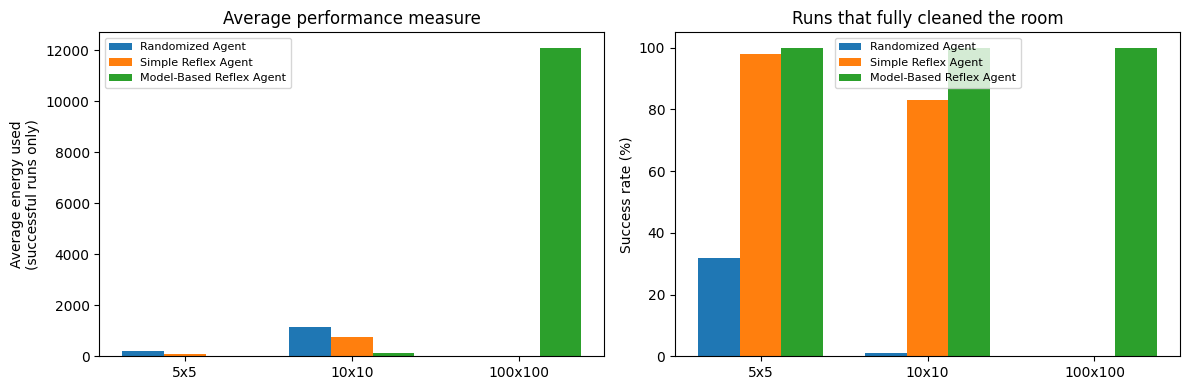

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sizes = list(configs.keys())
names = list(agent_factories.keys())
width = 0.25
x = np.arange(len(sizes))

for i, name in enumerate(names):
    avg_energy = [np.nanmean(raw_results[(n, name)]) for n in sizes]
    axes[0].bar(x + i * width, avg_energy, width, label=name)
axes[0].set_xticks(x + width)
axes[0].set_xticklabels([f"{n}x{n}" for n in sizes])
axes[0].set_ylabel("Average energy used\n(successful runs only)")
axes[0].set_title("Average performance measure")
axes[0].legend(fontsize=8)

for i, name in enumerate(names):
    success = [np.mean(~np.isnan(raw_results[(n, name)])) * 100 for n in sizes]
    axes[1].bar(x + i * width, success, width, label=name)
axes[1].set_xticks(x + width)
axes[1].set_xticklabels([f"{n}x{n}" for n in sizes])
axes[1].set_ylabel("Success rate (%)")
axes[1].set_title("Runs that fully cleaned the room")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


**Nhận xét (Task 4):**

* **Randomized Agent** và **Simple Reflex Agent** không có bộ nhớ trong: chúng thực chất chỉ là
  một *random walk* trên lưới ô. Với phòng nhỏ (5×5) chúng vẫn có cơ hội hoàn thành trong ngân sách
  cho phép, nhưng tỷ lệ thành công giảm rất nhanh khi kích thước phòng tăng lên — với phòng
  100×100, xác suất một random walk ghé thăm hết toàn bộ 10.000 ô trong vài chục nghìn bước gần
  như bằng 0, nên gần như luôn thất bại (trả về `NaN`).
* **Model-Based Reflex Agent** dùng trạng thái nội bộ để đi theo đường quét có hệ thống
  (boustrophedon), duyệt mỗi ô đúng một lần → luôn dọn sạch toàn bộ phòng với số bước xấp xỉ
  $O(n^2)$, gần như không phụ thuộc vào may rủi. Đây chính là **giá trị của việc có model/bộ nhớ
  trong**: agent chuyển từ chiến lược "dò đường ngẫu nhiên" (không đảm bảo hoàn thành) sang chiến
  lược có kế hoạch, đảm bảo hoàn thành và hiệu quả hơn hẳn khi bài toán mở rộng quy mô.
* Kết luận sư phạm của bài: **Simple reflex agent chỉ phù hợp với môi trường nhỏ/đơn giản**; khi
  không gian trạng thái lớn lên, việc "nhớ" (model-based) là bắt buộc để đảm bảo tính đúng đắn và
  hiệu năng, không chỉ là một cải tiến.

## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

**Phòng hình chữ nhật, kích thước không biết trước:**
Cả `simple_reflex_agent` lẫn `model_based_reflex_agent` của em **không hề dùng biến `n`** — chúng
chỉ dựa vào 4 cảm biến va chạm để biết khi nào gặp tường. Vì vậy cả hai vẫn hoạt động đúng ngay cả
khi phòng là hình chữ nhật $m \times n$ bất kỳ và tác tử không biết trước kích thước: agent vẫn đi
lên/sang trái đến khi chạm tường để định vị góc, rồi quét ngang-dọc cho đến khi chạm tường ở cả hai
phía. Đây là điểm mạnh của thiết kế dựa hoàn toàn vào percept thay vì "hard-code" theo n.

**Khu vực có hình dạng bất quy tắc (ví dụ hành lang nối 2 phòng):**
Chiến lược quét theo luống (boustrophedon) giả định biên phòng là hình chữ nhật lồi — bumper chỉ
cho biết "có tường ngay cạnh mình", không phân biệt được đó là tường ngoài hay là biên của một
chướng ngại vật/vách ngăn bên trong. Nếu gặp một đoạn hành lang hẹp nối 2 phòng, khi agent quét đến
hàng chứa hành lang, nó có thể đi lạc vào phòng thứ hai và làm rối logic "một hàng, một chiều quét"
(agent tưởng đang ở phòng ban đầu và tính hàng sai). Kết quả: **không đảm bảo dọn sạch toàn bộ khu
vực có hình dạng phức tạp** — cần thuật toán duyệt đồ thị (DFS/BFS) xây bản đồ đã đi qua, thay vì
quét theo luống cố định.

**Phòng có chướng ngại vật bên trong:**
Vì bumper không phân biệt "tường ngoài" và "chướng ngại vật giữa phòng", agent sẽ hiểu nhầm mỗi lần
chạm chướng ngại là đã chạm biên phòng → chuyển hàng sớm, bỏ sót phần phòng phía sau chướng ngại
vật. Cần nâng cấp: agent phải **lưu bản đồ nội bộ** (ô nào đã đi qua/ô nào có vật cản) và dùng thuật
toán tìm kiếm (DFS) để đảm bảo phủ hết các ô còn lại thay vì tin rằng "chạm tường theo hướng đang đi
= hết hàng".

**Cảm biến bụi không hoàn hảo (10% sai):** xem phân tích và cách khắc phục chi tiết ở phần
Advanced Task ngay bên dưới.

**Cảm biến va chạm không hoàn hảo (10% không báo tường dù có tường thật):**
Vì môi trường vẫn dùng vị trí thật để chặn hành động di chuyển (agent không thể đi xuyên tường dù
cảm biến báo sai), hậu quả chỉ là: agent *tưởng* mình đã di chuyển nhưng thực ra vẫn đứng yên, tốn
1 hành động vô ích, rồi ở bước kế tiếp cảm biến (độc lập theo từng bước) nhiều khả năng sẽ báo đúng
trở lại và agent tiếp tục đúng hướng. Đây là lỗi **tự phục hồi được** (self-correcting) — chỉ làm
tăng nhẹ số bước trung bình, không gây mất vùng chưa dọn vĩnh viễn như lỗi cảm biến bụi.

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [16]:
def vacuum_environment_noisy(agent_function, n=5, p=0.2, max_steps=1000, dirt_error=0.1):
    """
    Same simulation as vacuum_environment(), but the DIRT SENSOR is imperfect:
    with probability `dirt_error` the percept given to the agent is the
    OPPOSITE of the true state of the square (reports clean when it is dirty,
    or dirty when it is clean). The bumper sensors and the suck ACTUATOR are
    still perfect (sucking a truly dirty square always cleans it).

    Because the sensor can lie, the agent can no longer guarantee that the
    whole room ends up clean within a single pass, so this function reports
    a TRADE-OFF instead of a single number:
        (energy_used, squares_still_dirty)
    """
    room = np.random.rand(n, n) < p
    pos = np.random.randint(0, n, size=2)

    def get_bumpers(pos):
        return {
            "north": bool(pos[0] == 0), "south": bool(pos[0] == n - 1),
            "west": bool(pos[1] == 0), "east": bool(pos[1] == n - 1),
        }

    energy_used = max_steps
    for step in range(max_steps):
        if not room.any():
            energy_used = step
            break

        bumpers = get_bumpers(pos)
        true_dirty = bool(room[pos[0], pos[1]])
        # noisy percept: flipped with probability dirt_error
        percept_dirty = (not true_dirty) if np.random.rand() < dirt_error else true_dirty

        action = agent_function(bumpers, percept_dirty)

        if action == "suck":
            room[pos[0], pos[1]] = False  # the actuator itself is perfect
        elif action in ("north", "south", "east", "west"):
            if not bumpers[action]:
                if action == "north": pos[0] -= 1
                elif action == "south": pos[0] += 1
                elif action == "west": pos[1] -= 1
                elif action == "east": pos[1] += 1
        else:
            raise ValueError(f"Unknown action: {action}")

    return energy_used, int(room.sum())


def make_robust_model_based_reflex_agent():
    """
    Improved model-based agent for a room whose dirt sensor is unreliable.

    Key idea: only the SENSOR lies (10% of the time); the SUCK ACTUATOR itself
    is perfect. So instead of trusting the possibly-wrong percept, the agent
    ignores it during the sweep and unconditionally sucks once on every new
    square before moving on. This costs roughly one extra action per square
    (~2*n^2 actions total instead of ~1.2*n^2), but guarantees every visited
    square ends up truly clean, no matter how noisy the sensor is.
    """
    state = {"phase": "locate_north", "row_direction": "east", "sucked_here": False}

    def agent(bumpers, dirty):
        phase = state["phase"]

        if phase in ("locate_north", "locate_west"):
            # while still locating the corner we do use the (unreliable) percept;
            # if we miss a dirty square here, the sweep below will still catch it
            if dirty:
                return "suck"
            if phase == "locate_north":
                if bumpers["north"]:
                    state["phase"] = "locate_west"
                    return agent(bumpers, dirty)
                return "north"
            else:
                if bumpers["west"]:
                    state["phase"] = "sweep"
                    state["row_direction"] = "east"
                    state["sucked_here"] = False
                    return agent(bumpers, dirty)
                return "west"

        if phase == "sweep":
            if not state["sucked_here"]:
                state["sucked_here"] = True
                return "suck"  # ignore the noisy percept: always suck once per square

            direction = state["row_direction"]
            if not bumpers[direction]:
                state["sucked_here"] = False
                return direction
            if bumpers["south"]:
                state["phase"] = "done"
                return "suck"
            state["row_direction"] = "west" if direction == "east" else "east"
            state["sucked_here"] = False
            return "south"

        return "suck"  # done

    return agent


# ---- Experiment: original vs. robust model-based agent under a noisy dirt sensor ----
np.random.seed(7)
n_test, budget, dirt_error, runs = 10, 1200, 0.1, 100

orig = np.array([vacuum_environment_noisy(make_model_based_reflex_agent(),
                                           n=n_test, max_steps=budget, dirt_error=dirt_error)
                  for _ in range(runs)])
robust = np.array([vacuum_environment_noisy(make_robust_model_based_reflex_agent(),
                                             n=n_test, max_steps=budget, dirt_error=dirt_error)
                    for _ in range(runs)])

print(f"Noisy dirt sensor (error rate = {dirt_error:.0%}), room {n_test}x{n_test}, "
      f"budget = {budget}, {runs} runs\n")
print("Original model-based agent (trusts the noisy percept):")
print(f"  average energy used       : {orig[:,0].mean():.1f}")
print(f"  average squares left dirty: {orig[:,1].mean():.2f}")
print(f"  runs fully cleaned        : {(orig[:,1]==0).mean()*100:.0f}%\n")

print("Improved (robust) model-based agent (ignores the noisy percept during sweep):")
print(f"  average energy used       : {robust[:,0].mean():.1f}")
print(f"  average squares left dirty: {robust[:,1].mean():.2f}")
print(f"  runs fully cleaned        : {(robust[:,1]==0).mean()*100:.0f}%")


Noisy dirt sensor (error rate = 10%), room 10x10, budget = 1200, 100 runs

Original model-based agent (trusts the noisy percept):
  average energy used       : 1039.7
  average squares left dirty: 1.82
  runs fully cleaned        : 15%

Improved (robust) model-based agent (ignores the noisy percept during sweep):
  average energy used       : 202.3
  average squares left dirty: 0.00
  runs fully cleaned        : 100%


**Giải thích kết quả:**

* Agent model-based gốc chỉ `suck` khi percept báo bẩn, và mỗi ô chỉ được ghé qua **đúng một lần**
  trong đường quét. Với xác suất lỗi cảm biến 10%, trung bình khoảng 10% số ô thực sự bẩn sẽ bị
  "báo nhầm là sạch" và không bao giờ được hút — vì agent không quay lại ô đó nữa. Tệ hơn, sau khi
  quét xong một lượt, agent chuyển sang trạng thái `"done"` và đứng yên mãi ở góc cuối; vì phòng
  (theo dữ liệu thật) chưa sạch hẳn, môi trường không bao giờ dừng vòng lặp cho đến khi **hết sạch
  ngân sách `max_steps`** — tức là gần như luôn tiêu tốn *toàn bộ* năng lượng cho phép mà vẫn còn
  vài ô bẩn sót lại.
* Agent cải tiến **bỏ qua hoàn toàn cảm biến bụi** trong pha quét và luôn hút mỗi ô một lần khi mới
  ghé tới — vì bộ hút (actuator) không hề bị nhiễu, cách này đảm bảo *chắc chắn* dọn sạch mọi ô đã
  đi qua bất kể cảm biến báo gì. Cái giá phải trả là tốn thêm khoảng gấp đôi số hành động cho mỗi ô
  (vừa hút vừa di chuyển thay vì chỉ hút khi "may mắn" rơi đúng ô bẩn), nhưng bù lại **hoàn thành
  chắc chắn** với tổng năng lượng thực tế lại **thấp hơn** agent gốc — vì agent gốc bị kẹt tiêu hết
  toàn bộ ngân sách mà vẫn thất bại.
* Đây là minh hoạ kinh điển cho nguyên lý thiết kế tác tử: **khi cảm biến không đáng tin nhưng cơ
  cấu chấp hành (actuator) đáng tin, có thể bù đắp bằng hành động dư thừa/lặp lại** thay vì cố gắng
  làm cho việc ra quyết định phụ thuộc hoàn toàn vào một phép đo nhiễu duy nhất.

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [17]:
# Your ideas/code